# COMIND Subtyping Demo (refactored fitter)
This notebook generates synthetic longitudinal data and fits the refactored `SubtypingEM` (`fit` helpers, `assignments.py`, `model_selection.py`, staged `theta_solver_stages` instead of `jac_toggle`).


In [41]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import random
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, adjusted_rand_score

from COMIND_transformer.model_generator import generate_logistic_model, get_adjacency_matrix, create_patient_list
from COMIND_transformer.synthetic_data_generator import generate_synthetic_data
from COMIND_transformer.visualization import * 
from COMIND_transformer.utils import *
from COMIND_transformer.subtyping_em_transformer import SubtypingEM

np.set_printoptions(precision=4)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
# data params
n_biomarkers = 3
t_max = 7
t_span = np.linspace(0, t_max, 800)
noise_level = 0.1
n_patients = 100 # was 200
n_patient_obs = 3
n_subtypes = 3 #3,4,5
rng = np.random.RandomState(75)
missing_frac = 0.15  # fraction of biomarker entries to set to NaN after generation

# ground-truth global self-propagation kappa (one per biomarker)
# similar scale to f, random in [0.0, 0.1]
# true_kappa = rng.uniform(0.0, 3, size=n_biomarkers)


For subtype data generation: different sets of trajectories are generated for each subtype. 
- K is held constant for each subtype
- f and scalar_K are different for each subtype

- removed variablity in time point, now they are in intervals of integer years to mirror ppmi data.
- only one copy of beta now generated instead of three identical copies.


In [43]:
K = get_adjacency_matrix("random_offdiag", n_biomarkers, np.random.RandomState(75))

eigenvalues, eigenvectors = np.linalg.eig(K)

# print(f"eigenvalues: {eigenvalues}")
# print(f"eigenvectors: {eigenvectors}")

v = eigenvectors[:, 0]

if np.abs(np.min(v)) > np.abs(np.max(v)):
    v = -v

v_normalized = v / np.linalg.norm(v)
#print(v_normalized)
v_normalized = v_normalized + rng.uniform(-0.25, 0.25, size=n_biomarkers) # noise
np.clip(v_normalized, 0.0, np.inf)
print(f"kappa: {v_normalized}")

true_kappa = v_normalized 
v_normalized[1] = 0.0
np.fill_diagonal(K, v_normalized)

print(K)

kappa: [0.7256 0.3439 0.6498]
[[0.7256 1.     0.7805]
 [1.     0.     0.1159]
 [0.7805 0.1159 0.6498]]


SUBTYPE 0:
f: [0.  0.  0.3]
a = 4.676436127196727, b = 6.421955999238555


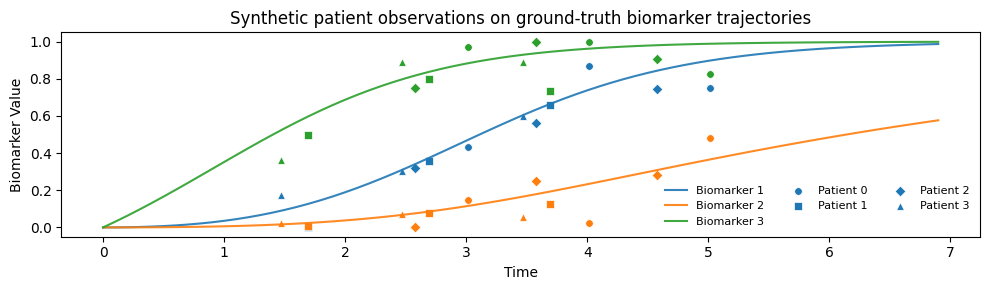

2.0825497783678255
SUBTYPE 1:
f: [0.3 0.  0. ]
a = 1.1927249100009507, b = 6.8096301386771785


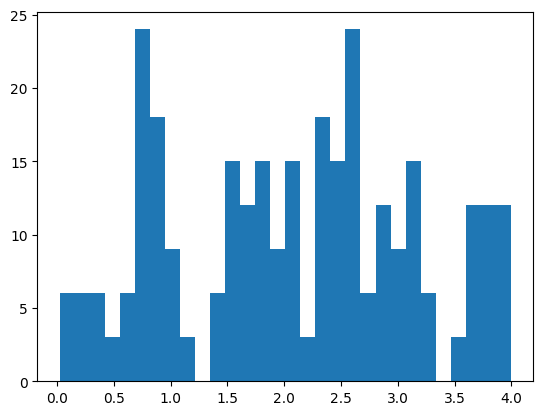

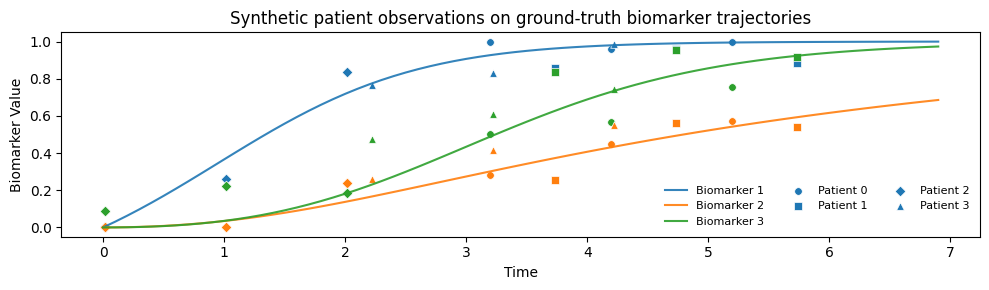

1.980709205848541
SUBTYPE 2:
f: [0.  0.3 0. ]
a = 3.0026725053615246, b = 4.680674259481151


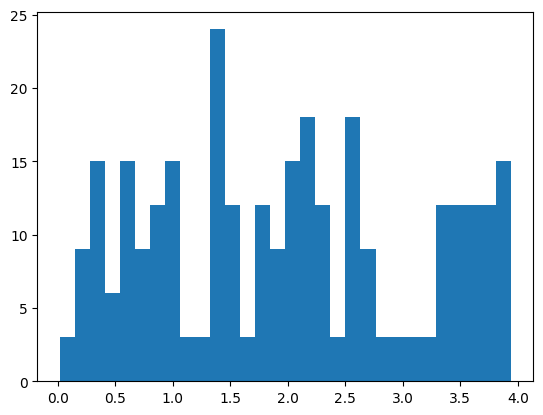

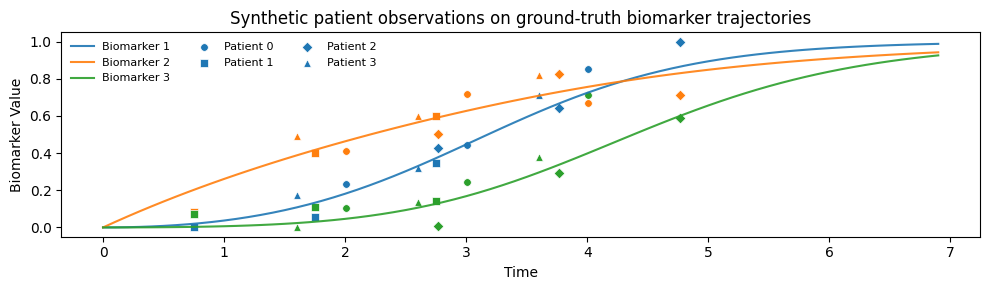

2.006035437041956
Missing 300/2700 biomarker entries (11.1%)
Observed counts per biomarker: [782 808 810]


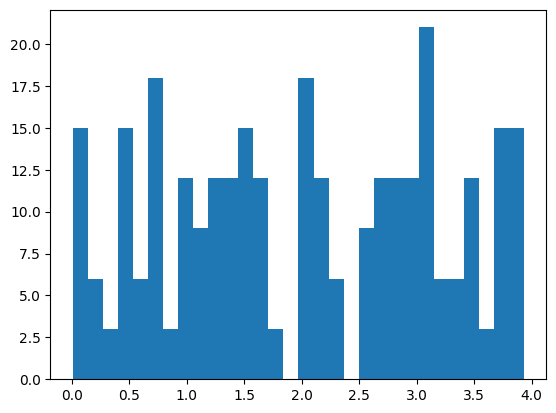

In [44]:
scalar_K_list = [0.2, 0.2, 0.2]
f_list = []
for _ in range(n_subtypes):
    f_list.append(rng.gamma(shape=2, scale=0.005, size=n_biomarkers))

f_list = [np.array([0.0, 0.0, 0.3]), np.array([0.3, 0.0, 0.0]), np.array([0.0, 0.3, 0.0])]

X = []
y = []

for subtype in range(n_subtypes):
    print(f"SUBTYPE {subtype}:")
    t, x_true, K, x0, f, scalar_K, kappa_true  = generate_logistic_model(
        n_biomarkers=n_biomarkers,
        scalar_K=scalar_K_list[subtype],
        t_max=t_max,
        K=K,
        f=f_list[subtype],
        kappa=true_kappa,
    )

    print(f"f: {f}")
    
    df, cog_a, cog_b = generate_synthetic_data(
        n_biomarkers = n_biomarkers,
        t_max = t_max, 
        noise_level = noise_level,
        n_patients = n_patients,
        n_patient_obs = n_patient_obs,
        x_true=x_true, 
        t=t,
        rng = np.random.RandomState(75 + subtype + 2),
    )

    plot_true_observations(df, t, x_true, patient_idx=[0,1,2,3])

    biomarker_cols = [col for col in df.columns if col.startswith("biomarker_")]

    X_obs = df[biomarker_cols].values   # (n_obs, n_biomarkers)
    dt = df["dt"].values                # (n_obs,)
    ids = df["patient_id"].values + subtype * n_patients # (n_obs,),  `+ subtype * n_patients` is for ensuring all ids are unique
    cog = df["cognitive_score"].values  # (n_obs,)
    beta_true = df["beta_true"].values  # (n_obs)
    
    plt.hist(beta_true, bins=30)
    print(np.mean(beta_true))
    
    X_subtype = create_patient_list(X_obs, ids, dt, cog, initial_beta=None)
    
    for p in X_subtype: # tag each patient with true subtype for later eval
        p["subtype_true"] = int(subtype)
    X += X_subtype # pythonic concatenate list syntactic sugar
    
    y.append(beta_true[::n_patient_obs] )
    
X = np.asarray(X)
y = np.concatenate(y)

# Punch missing biomarker entries into otherwise-complete visits.
# Whole missing visits are already handled by omitting a row; this is
# per-entry NaN (MAR/MCAR) for SubtypingEM's masked likelihood.
rng_miss = np.random.default_rng(75)
n_nan_total = 0
n_entries = 0
for p in X:
    X_i = np.asarray(p["X_obs"], dtype=float).copy()
    n_entries += X_i.size
    n_nan = min(int(round(missing_frac * X_i.size)), X_i.size - 1)
    if n_nan > 0:
        idx = rng_miss.choice(X_i.size, size=n_nan, replace=False)
        X_i.ravel()[idx] = np.nan
        if not np.any(np.isfinite(X_i)):
            X_i.flat[0] = np.asarray(p["X_obs"], dtype=float).flat[0]
    p["X_obs"] = X_i
    n_nan_total += int(np.isnan(X_i).sum())

stacked = np.vstack([p["X_obs"] for p in X])
n_obs_per_b = np.sum(np.isfinite(stacked), axis=0)
print(
    f"Missing {n_nan_total}/{n_entries} biomarker entries "
    f"({100.0 * n_nan_total / n_entries:.1f}%)"
)
print(f"Observed counts per biomarker: {n_obs_per_b}")
if np.any(n_obs_per_b < 2):
    raise ValueError(
        f"A biomarker has fewer than 2 observed values after masking: {n_obs_per_b}"
    )


In [45]:
all_dt = np.concatenate([p["dt"] for p in X])
all_cog = np.concatenate([p["cog"] for p in X])
all_ids_array = np.concatenate([[p["id"]] * len(p["dt"]) for p in X])

initial_beta, pid_to_beta, result = fit_mixedlm_beta_from_clinical(
    ids=all_ids_array,
    dt=all_dt,
    cog=all_cog,
    t_max=t_max,
    verbose=True,
    rng=np.random.default_rng(75)
)

unique_ids = np.unique([p["id"] for p in X])
beta_true_array = y
        
print(f"Initialized beta for {len(initial_beta)} patients")
print(f"Beta range: [{np.min(initial_beta):.2f}, {np.max(initial_beta):.2f}]")
print(f"True beta range: [{np.min(beta_true_array):.2f}, {np.max(beta_true_array):.2f}]")


beta_init summary: count    300.000000
mean       3.042049
std        1.677473
min        0.000000
25%        1.745121
50%        2.600821
75%        4.085345
max        7.000000
dtype: float64
Initialized beta for 300 patients
Beta range: [0.00, 7.00]
True beta range: [0.01, 3.99]


## Optuna with K-Fold Cross-Validation

One study per subtype count, stored in this folder. Set `RUN_OPTUNA = False` to load the saved best fit and skip straight to the plots.


In [46]:
# Initialize f for all models
f_init = initialize_f_eigen(K, n_subtypes=4, n_eigs=8, jitter=True, sparsity_mask=True, rng=np.random.RandomState(72))
if isinstance(f_init, list):
    f_init = f_init[0]

print(f_init)

# Add initial_beta to patient data
unique_ids = np.unique([p["id"] for p in X])
id_to_beta_idx = {pid: idx for idx, pid in enumerate(unique_ids)}
for p in X:
    p["initial_beta"] = initial_beta[id_to_beta_idx[p["id"]]]
    # SubjectEM also expects beta_pred (use initial_beta as starting point)
    p["beta_pred"] = float(initial_beta[id_to_beta_idx[p["id"]]])

# Add initialization fields required by SubjectEM (for burn-in initialization)
# These are used as starting points for the per-patient SubjectEM burn-in
s_init = np.ones(n_biomarkers)  # Default initialization for s
scalar_K_init = float(np.nanmax([np.nanmax(p["X_obs"]) for p in X]))  # Use max observed value

for p in X:
    p["f_init"] = f_init[0].copy()   # (3,) for SubjectEM  # Use the f_init from eigen initialization
    p["s_init"] = s_init.copy()
    p["scalar_K_init"] = scalar_K_init


[[0.7406 0.4637 0.    ]
 [0.6344 0.6321 0.    ]
 [0.     0.5158 0.7864]
 [0.8157 0.4777 0.    ]]


In [47]:
# One Optuna study per subtype count. n_subtypes is not searched.
# Set RUN_OPTUNA = False to load best_result.joblib and skip the search (plots only).
from pathlib import Path

RUN_OPTUNA = True
candidate_n_subtypes = [2, 3, 4]
n_optuna_trials = 5  # additional trials per subtype count when RUN_OPTUNA is True
n_splits = 3

def _notebook_dir() -> Path:
    """Directory of the notebook that is running, so a copied folder keeps its own journal."""
    try:
        from IPython import get_ipython
        ip = get_ipython()
    except Exception:
        ip = None
    if ip is not None:
        nb_path = ip.user_ns.get("__vsc_ipynb_file__")
        if nb_path:
            return Path(nb_path).resolve().parent
    try:
        import ipynbname
        return Path(ipynbname.path()).resolve().parent
    except Exception:
        pass
    cwd = Path.cwd().resolve()
    if any(cwd.glob("*.ipynb")):
        return cwd
    raise RuntimeError(
        "Could not find this notebook's folder. Open and run it from the editor."
    )

STUDY_DIR = _notebook_dir()
RESULT_PATH = STUDY_DIR / "best_result.joblib"

def suggest_hyperparams(trial):
    """Penalties. n_subtypes, lambda_cog, and epsilon are not suggestions."""
    return {
        "lambda_f": trial.suggest_float("lambda_f", 1e-1, 2.0, log=True),
        "lambda_kappa": trial.suggest_float("lambda_kappa", 1e-1, 2.0, log=True),
        "lambda_scalar": trial.suggest_float("lambda_scalar", 0.0, 1.0),
        "lambda_jsd": trial.suggest_float("lambda_jsd", 0.0, 1.0),
    }

print(f"Study dir: {STUDY_DIR}")
print(f"RUN_OPTUNA={RUN_OPTUNA}  n_subtypes={candidate_n_subtypes}")
print(f"{n_optuna_trials} new trials each, {n_splits}-fold CV" if RUN_OPTUNA else f"Will load {RESULT_PATH.name}")
print("Searched: lambda_f, lambda_kappa, lambda_scalar, lambda_jsd")
print("Fixed: lambda_cog=0, epsilon=1e-3; n_subtypes chosen by BIC")


Study dir: /home/dsemchin/COMIND/notebooks/synthetic-experiments/2026_10_13_jax_solver_test
RUN_OPTUNA=True  n_subtypes=[2, 3, 4]
5 new trials each, 3-fold CV
Searched: lambda_f, lambda_kappa, lambda_scalar, lambda_jsd
Fixed: lambda_cog=0, epsilon=1e-3; n_subtypes chosen by BIC


$$SSE_b = \sum_{r} \big( X_{obs} - X_{pred} \big)^2$$

In [48]:
import time
import joblib
import optuna
from sklearn.model_selection import KFold

optuna.logging.set_verbosity(optuna.logging.WARNING)

def _subset_patients(patients, indices):
    return [patients[i] for i in indices]

def _study_db(K_val):
    return (STUDY_DIR / f"optuna_n_subtypes_{K_val}.db").resolve()

def _open_study(K_val):
    """Fresh study on first use; later runs append trials to the same file."""
    storage = f"sqlite:///{_study_db(K_val)}"
    study_name = f"n_subtypes_{K_val}"
    try:
        return optuna.load_study(study_name=study_name, storage=storage)
    except KeyError:
        return optuna.create_study(
            study_name=study_name,
            storage=storage,
            direction="minimize",
            sampler=optuna.samplers.TPESampler(seed=75, n_startup_trials=5),
        )

def _release_model(model):
    model._checkpoint_snapshot = None
    model._checkpoint_X = None
    model._checkpoint_term_handler = None
    return model

def save_best_result():
    for model in best_model_per_K.values():
        _release_model(model)
    payload = {
        "best_model": best_model,
        "best_model_per_K": best_model_per_K,
        "best_n_subtypes": best_n_subtypes,
        "best_params_per_K": best_params_per_K,
        "bic_per_K": bic_per_K,
        "best_cv_lse_per_K": best_cv_lse_per_K,
        "candidate_n_subtypes": list(candidate_n_subtypes),
        "X": X,
        "f_list": f_list,
        "f_init": f_init,
        "scalar_K_list": scalar_K_list,
        "true_kappa": true_kappa,
        "K": K,
        "t_span": t_span,
        "n_biomarkers": n_biomarkers,
        "beta_true_array": beta_true_array,
        "initial_beta": initial_beta,
    }
    joblib.dump(payload, RESULT_PATH)
    print(f"Saved best result to {RESULT_PATH}")

def load_best_result():
    if not RESULT_PATH.exists():
        raise FileNotFoundError(
            f"No saved result at {RESULT_PATH}. Set RUN_OPTUNA = True and run this cell once."
        )
    payload = joblib.load(RESULT_PATH)
    print(f"Loaded {RESULT_PATH}")
    print(f"  n_subtypes={payload['best_n_subtypes']}  BIC per K={payload['bic_per_K']}")
    print(f"  CV LSE per K={payload['best_cv_lse_per_K']}")
    return payload

LOADED_BEST_RESULT = not RUN_OPTUNA

if not RUN_OPTUNA:
    _loaded = load_best_result()
    best_model = _loaded["best_model"]
    best_model_per_K = _loaded["best_model_per_K"]
    best_n_subtypes = _loaded["best_n_subtypes"]
    best_params_per_K = _loaded["best_params_per_K"]
    bic_per_K = _loaded["bic_per_K"]
    best_cv_lse_per_K = _loaded["best_cv_lse_per_K"]
    candidate_n_subtypes = _loaded["candidate_n_subtypes"]
    X = _loaded["X"]
    f_list = _loaded["f_list"]
    f_init = _loaded["f_init"]
    scalar_K_list = _loaded["scalar_K_list"]
    true_kappa = _loaded["true_kappa"]
    K = _loaded["K"]
    t_span = _loaded["t_span"]
    n_biomarkers = _loaded["n_biomarkers"]
    beta_true_array = _loaded["beta_true_array"]
    initial_beta = _loaded["initial_beta"]
    studies_per_K = {}
    for K_val in candidate_n_subtypes:
        db = _study_db(K_val)
        if db.exists():
            studies_per_K[K_val] = optuna.load_study(
                study_name=f"n_subtypes_{K_val}",
                storage=f"sqlite:///{db}",
            )
else:
    fixed_params = {
        "theta_solver_stages": ("lbfgs_exact",),
        "backend": "jax",
        "max_iter": 15,
        "t_max": t_max,
        "step": 0.01,
        "K": K,
        "assignments_jitter": False,
        "jitter_iter": 0,
        "verbose": 0,
        "lambda_cog": 0.0,
        "epsilon": 1e-3,
    }
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=75)

    def cv_mean_lse(K_val, hyperparams):
        """Mean held-out reconstruction LSE (estimator.score is negative LSE)."""
        fold_lse = []
        for train_idx, val_idx in kf.split(np.arange(len(X))):
            model = SubtypingEM(
                n_subtypes=K_val,
                initial_f=np.asarray(f_init[:K_val]),
                rng=np.random.default_rng(75),
                **fixed_params,
                **hyperparams,
            )
            model.fit(_subset_patients(X, train_idx))
            fold_lse.append(-model.score(_subset_patients(X, val_idx)))
        return float(np.mean(fold_lse))

    bic_per_K = {}
    best_model_per_K = {}
    best_params_per_K = {}
    best_cv_lse_per_K = {}
    studies_per_K = {}
    X_full = list(X) if isinstance(X, np.ndarray) else X

    for K_val in candidate_n_subtypes:
        study = _open_study(K_val)
        n_done = sum(t.state.name == "COMPLETE" for t in study.trials)
        print(
            f"\nOptuna n_subtypes={K_val}: {n_done} completed trials in {_study_db(K_val).name}"
        )
        print(f"  adding {n_optuna_trials} trials, {n_splits}-fold CV")

        def objective(trial, K_val=K_val):
            hyperparams = suggest_hyperparams(trial)
            try:
                mean_lse = cv_mean_lse(K_val, hyperparams)
            except Exception as exc:
                print(f"  trial {trial.number} failed: {exc}")
                return float("inf")
            print(f"  trial {trial.number}: mean CV LSE = {mean_lse:.6f}  params = {hyperparams}")
            return mean_lse

        t0 = time.perf_counter()
        study.optimize(objective, n_trials=n_optuna_trials, show_progress_bar=False)
        elapsed = time.perf_counter() - t0
        study.trials_dataframe().to_csv(STUDY_DIR / f"optuna_n_subtypes_{K_val}.csv", index=False)

        best_hyper = dict(study.best_params)
        print(f"  Best CV LSE: {study.best_value:.6f}")
        print(f"  Best params: {best_hyper}")
        print("  Refitting that trial on the full data for BIC")

        best_est = SubtypingEM(
            n_subtypes=K_val,
            initial_f=np.asarray(f_init[:K_val]),
            rng=np.random.default_rng(75),
            **fixed_params,
            **best_hyper,
        )
        best_est.verbose = 1
        best_est.fit(X_full)

        bic_per_K[K_val] = float(best_est.bic_)
        best_model_per_K[K_val] = best_est
        best_params_per_K[K_val] = best_hyper
        best_cv_lse_per_K[K_val] = float(study.best_value)
        studies_per_K[K_val] = study

        print(f"  Full-data LSE: {best_est.lse_history[-1]:.6f}, BIC: {best_est.bic_:.4f}")
        print(f"  Elapsed: {elapsed / 60:.2f} min")

    best_n_subtypes = min(bic_per_K, key=bic_per_K.get)
    best_model = best_model_per_K[best_n_subtypes]
    print(f"\nBest CV LSE per K: {best_cv_lse_per_K}")
    print(f"BIC per K: {bic_per_K}")
    print(f"Chosen n_subtypes: {best_n_subtypes} (lowest BIC among best-LSE runs)")
    save_best_result()



Optuna n_subtypes=2: 10 completed trials in optuna_n_subtypes_2.db
  adding 5 trials, 3-fold CV


Estimating beta and subtype assignments: 100%|██████████| 100/100 [00:00<00:00, 148.29it/s]


  trial 10: mean CV LSE = 19.570272  params = {'lambda_f': 0.5550387781013038, 'lambda_kappa': 0.8737472803891687, 'lambda_scalar': 0.41369543033349687, 'lambda_jsd': 0.9811418277588334}


Estimating beta and subtype assignments: 100%|██████████| 100/100 [00:00<00:00, 126.41it/s]


  trial 11: mean CV LSE = 18.522360  params = {'lambda_f': 0.38187787822348707, 'lambda_kappa': 0.11883160381133354, 'lambda_scalar': 0.9695107844839757, 'lambda_jsd': 0.011657901995695163}


...

  trial 13: mean CV LSE = 5.777173  params = {'lambda_f': 0.10370573267619684, 'lambda_kappa': 0.10354398436456297, 'lambda_scalar': 0.031211249946188513, 'lambda_jsd': 0.7770203728718383}


Estimating beta and subtype assignments: 100%|██████████| 100/100 [00:01<00:00, 66.67it/s]


  trial 14: mean CV LSE = 5.816936  params = {'lambda_f': 0.14387469575845432, 'lambda_kappa': 0.21159653253396235, 'lambda_scalar': 0.004662475009414729, 'lambda_jsd': 0.4720066423246248}
  Best CV LSE: 5.777173
  Best params: {'lambda_f': 0.10370573267619684, 'lambda_kappa': 0.10354398436456297, 'lambda_scalar': 0.031211249946188513, 'lambda_jsd': 0.7770203728718383}
  Refitting that trial on the full data for BIC


100%|██████████| 15/15 [00:07<00:00,  2.02it/s]

  Full-data LSE: 17.529993, BIC: 521.6805
  Elapsed: 2.10 min

Best CV LSE per K: {2: 18.522359985481074, 3: 5.844465211100957, 4: 5.7771725719178955}
BIC per K: {2: 1232.7352563095562, 3: 521.5719123984013, 4: 521.6805376741752}
Chosen n_subtypes: 3 (lowest BIC among best-LSE runs)
Saved best result to /home/dsemchin/COMIND/notebooks/synthetic-experiments/2026_10_13_jax_solver_test/best_result.joblib


In [49]:
# Best model and K were set in the previous cell (Option 1). Summary:
print(f"Best n_subtypes: {best_n_subtypes}")
print(f"Best params for chosen K: {best_params_per_K[best_n_subtypes]}")
print(f"BIC of best model: {best_model.bic_:.4f}")
if hasattr(best_model, 'lse_history') and len(best_model.lse_history) > 0:
    print(f"Final LSE: {best_model.lse_history[-1]:.6f}")

Best n_subtypes: 3
Best params for chosen K: {'lambda_f': 0.2965762478875874, 'lambda_kappa': 0.10023023145291123, 'lambda_scalar': 0.0042228020358456, 'lambda_jsd': 0.038462011042292125}
BIC of best model: 521.5719
Final LSE: 18.448944


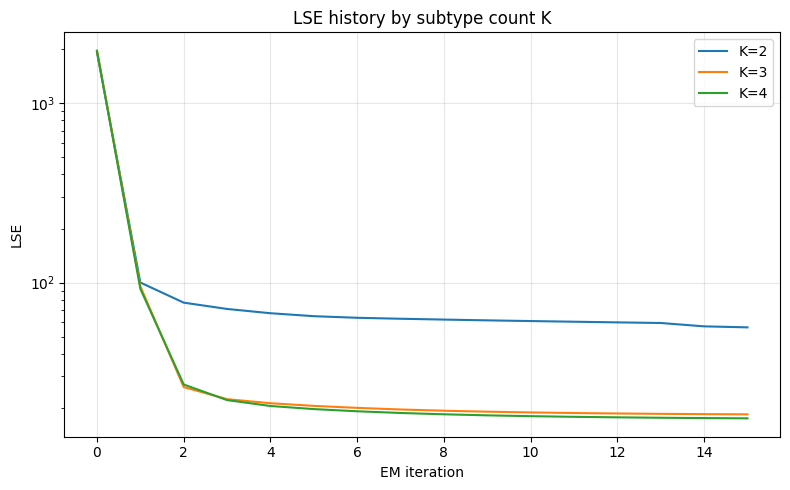

In [50]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
for K_val in candidate_n_subtypes:
    m = best_model_per_K[K_val]
    if hasattr(m, 'lse_history') and m.lse_history is not None and len(m.lse_history) > 0:
        ax.plot(m.lse_history, label=f'K={K_val}')
ax.set_xlabel('EM iteration')
ax.set_ylabel('LSE')
ax.set_title('LSE history by subtype count K')
ax.legend()
ax.grid(True, alpha=0.3)
plt.yscale('log')
plt.tight_layout()
plt.show()

## Evaluate Best Model

When `RUN_OPTUNA` is True, refit the BIC-selected model on the full data and update `best_result.joblib`. When it is False, the loaded fit is left as-is for plotting.


In [51]:
# Refit only after a new Optuna run. A loaded result is already the full-data fit.
X_list = list(X) if isinstance(X, np.ndarray) else X
best_model = best_model_per_K[best_n_subtypes]

if RUN_OPTUNA:
    best_model.verbose = 1
    best_model.fit(X_list)
    best_model_per_K[best_n_subtypes] = best_model
    bic_per_K[best_n_subtypes] = float(best_model.bic_)
    save_best_result()
else:
    print("Loaded saved fit; skipping refit.")

print(f"\nBest model final LSE: {best_model.lse_history[-1]:.6f}")
print(f"BIC: {best_model.bic_:.4f}")


100%|██████████| 15/15 [00:06<00:00,  2.50it/s]

Saved best result to /home/dsemchin/COMIND/notebooks/synthetic-experiments/2026_10_13_jax_solver_test/best_result.joblib

Best model final LSE: 17.811053
BIC: 505.0320



Subtype mapping (fitted → true): [1 2 0]
  Fitted subtype 0 → True subtype 1
  Fitted subtype 1 → True subtype 2
  Fitted subtype 2 → True subtype 0
Overlap-based mapping (fitted --> true): [1 2 0]

Fitted Subtype 0 -> True Subtype 1:
  f_fitted:      [0.2814 0.0442 0.0251]
  f_true:        [0.3 0.  0. ]

Fitted Subtype 1 -> True Subtype 2:
  f_fitted:      [0.0149 0.2641 0.0057]
  f_true:        [0.  0.3 0. ]

Fitted Subtype 2 -> True Subtype 0:
  f_fitted:      [0.009  0.015  0.2006]
  f_true:        [0.  0.  0.3]

Global scalar_K:
  scalar_K_fitted: 0.075130
  scalar_K_true (mean): 0.200000
  scalar_K_true (per subtype): [0.2, 0.2, 0.2]

Global s:
  s_fitted:      [0.9679 0.8898 0.9606]
  s_true:        [1. 1. 1.]
Kappa:
	kappa_true: [1.0162 0.3017 0.8851]
	kappa_fit: [0.7256 0.     0.6498]


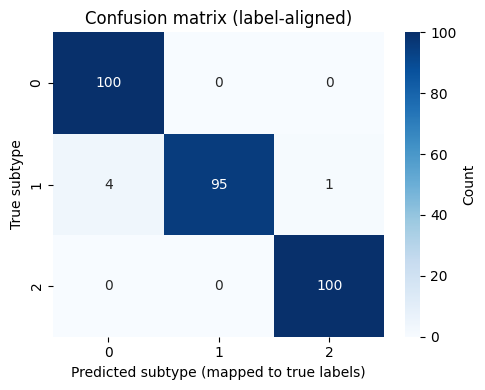

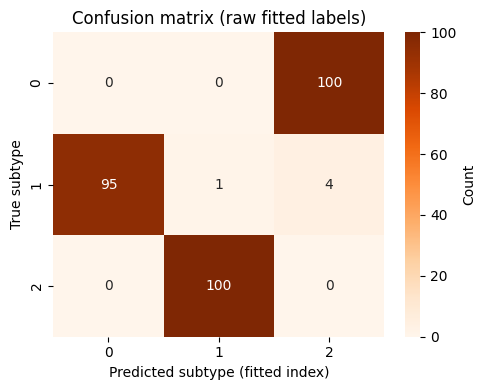


Adjusted Rand Index (mapped): 0.9507
BIC (training): 505.0320


In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
# Ensure list-of-dicts for evaluation helpers (utils.* imported in cell 1) (fit accepts list; avoid accidental np.asarray)
X_list = list(X) if isinstance(X, np.ndarray) else X

assignments_true = np.array([p["subtype_true"] for p in X_list])
beta_true_flat = np.ravel(np.asarray(beta_true_array))
n_true_subtypes = len(f_list)
n_fitted_subtypes = len(best_model.cluster_f)

# Fitted ÃÂ¢ÃÂÃÂ true permutation via f matching (also on best_model.compute_subtype_mapping)
subtype_mapping = best_model.compute_subtype_mapping(f_list, verbose=True)
mapped_assignments = subtype_mapping[best_model.final_assignments]

# Optional cross-check: assignment overlap mapping (can differ slightly from f-based)
subtype_mapping_overlap = get_subtype_mapping(
    best_model.final_assignments, assignments_true
)
print(f"Overlap-based mapping (fitted --> true): {subtype_mapping_overlap}")

print_parameter_comparison(
    fitted_f_list=best_model.cluster_f,
    fitted_scalar_K=best_model.final_scalar_K,
    fitted_s=best_model.final_s,
    true_f_list=f_list,
    true_scalar_K_list=scalar_K_list,
    true_s=np.ones(n_biomarkers),
    subtype_mapping=subtype_mapping,
    n_subtypes=n_fitted_subtypes,
)
print(f"Kappa:")
print(f"\tkappa_true: {best_model.final_kappa}")
print(f"\tkappa_fit: {true_kappa}")

# Confusion matrices (true subtype labels on rows)
true_tick = list(range(n_true_subtypes))

cm_mapped = confusion_matrix(
    assignments_true, mapped_assignments, labels=true_tick
)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm_mapped, annot=True, fmt="d", cmap="Blues", ax=ax,
    xticklabels=true_tick, yticklabels=true_tick,
    cbar_kws={"label": "Count"},
)
ax.set_xlabel("Predicted subtype (mapped to true labels)")
ax.set_ylabel("True subtype")
ax.set_title("Confusion matrix (label-aligned)")
plt.tight_layout()
plt.show()

fitted_tick = list(range(n_fitted_subtypes))
cm_raw = confusion_matrix(
    assignments_true, best_model.final_assignments, labels=fitted_tick
)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm_raw, annot=True, fmt="d", cmap="Oranges", ax=ax,
    xticklabels=fitted_tick, yticklabels=true_tick,
    cbar_kws={"label": "Count"},
)
ax.set_xlabel("Predicted subtype (fitted index)")
ax.set_ylabel("True subtype")
ax.set_title("Confusion matrix (raw fitted labels)")
plt.tight_layout()
plt.show()

ari = adjusted_rand_score(assignments_true, mapped_assignments)
print(f"\nAdjusted Rand Index (mapped): {ari:.4f}")
print(f"BIC (training): {best_model.bic_:.4f}")

In [53]:
# import seaborn as sns

# assignments_true = np.array([p["subtype_true"] for p in X])
# mapped_assignments = subtype_mapping[best_model.final_assignments]
# cm_mapped = confusion_matrix(assignments_true, mapped_assignments)

# fig, ax = plt.subplots(figsize=(3, 2.5))
# sns.heatmap(
#     cm_mapped,
#     annot=True,
#     fmt="d",
#     cmap="Blues",
#     ax=ax,
#     xticklabels=[0, 1, 2],
#     yticklabels=[0, 1, 2],
#     cbar_kws={"label": "Count"},
# )
# ax.set_xlabel("Predicted subtype", fontsize=9)
# ax.set_ylabel("True subtype", fontsize=9)
# ax.tick_params(axis="both", labelsize=8)
# plt.tight_layout()
# plt.savefig("confusion_matrix_mapped.pdf", bbox_inches="tight", dpi=300)
# plt.show()

In [54]:
if getattr(best_model, 'assignment_probabilities_', None) is not None:
    import matplotlib.pyplot as plt
    probs = best_model.assignment_probabilities_
    eps = 1e-12
    entropy_per_patient = -np.sum(probs * np.log(probs + eps), axis=1)
    mean_posterior_entropy = np.mean(entropy_per_patient)
    print(f"Mean posterior entropy: {mean_posterior_entropy:.4f}")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].hist(np.max(probs, axis=1), bins=20)
    axes[0].set_xlabel('assignment probability (confidence)')
    axes[0].set_ylabel('count')
    axes[0].set_title('max assignment probability per patient')
    axes[1].hist(entropy_per_patient, bins=20)
    axes[1].set_xlabel('posterior entropy')
    axes[1].set_ylabel('count')
    axes[1].set_title('posterior entropy per patient')
    plt.tight_layout()
    plt.show()

## Visualizations


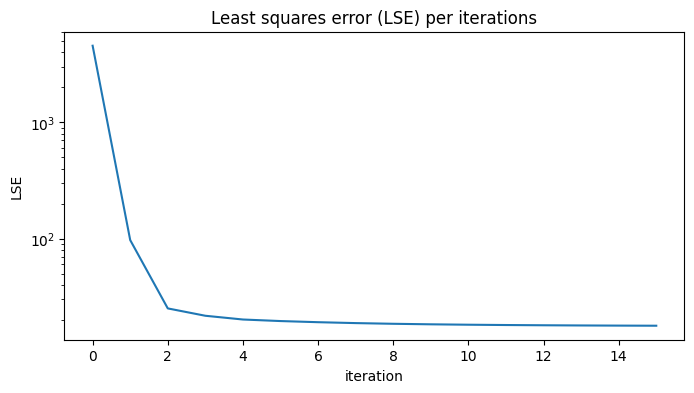

In [55]:
# Plot LSE history
plot_lse(best_model.lse_history)

/home/dsemchin/COMIND/COMIND_transformer/visualization.py:383: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/dsemchin/COMIND/COMIND_transformer/visualization.py:383: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/dsemchin/COMIND/COMIND_transformer/visualization.py:383: UserWarning: Glyph 134 (\x86) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/dsemchin/COMIND/COMIND_transformer/visualization.py:383: UserWarning: Glyph 146 (\x92) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/dsemchin/miniconda3/envs/comind/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/dsemchin/miniconda3/envs/comind/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw

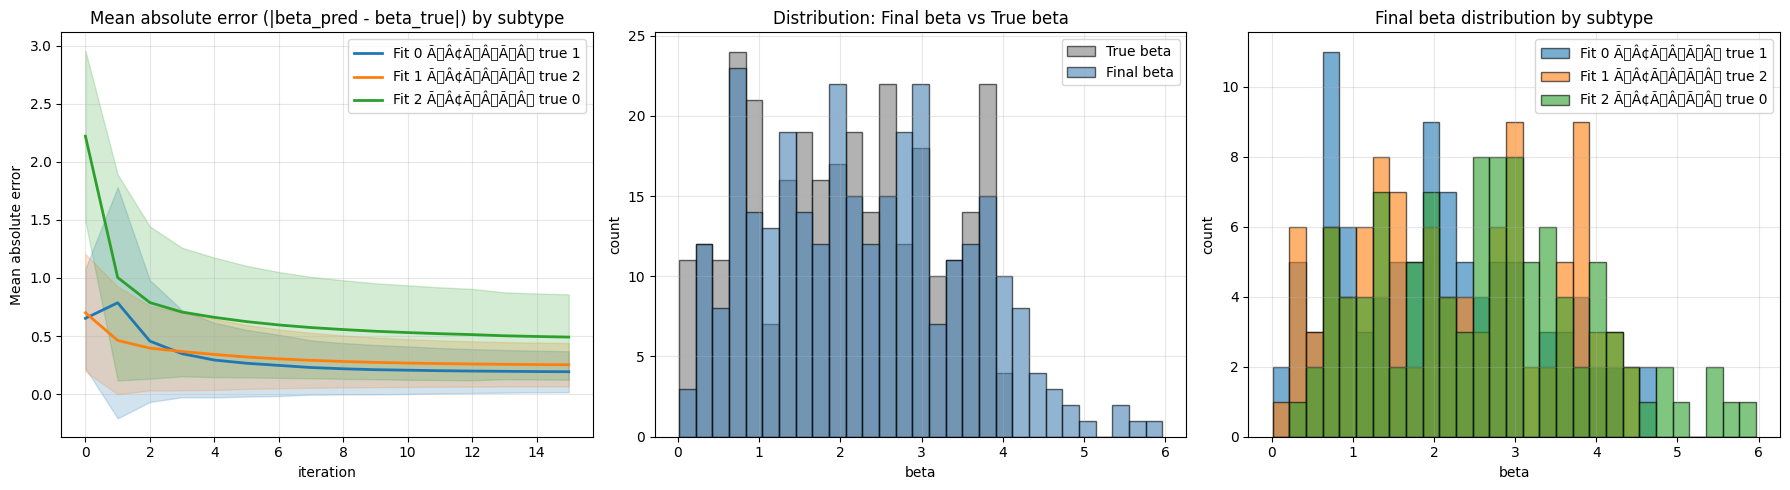

In [56]:
# Plot beta history by fitted subtype (legend shows f-based map to true)
fitted_labels = [
    f"Fit {i} ÃÂ¢ÃÂÃÂ true {int(subtype_mapping[i])}" for i in range(n_fitted_subtypes)
]
plot_beta_history_by_subtype(
    beta_history=best_model.beta_history,
    assignments=best_model.final_assignments,
    n_subtypes=n_fitted_subtypes,
    beta_true=beta_true_flat,
    subtype_labels=fitted_labels,
)


In [57]:
# Mean |beta error| by TRUE subtype (using mapped assignments)

beta_pred = best_model.beta_history[:, -1]
if beta_true_flat.shape[0] != beta_pred.shape[0]:
    raise ValueError("beta_true_array length must match number of patients.")
abs_err = np.abs(beta_pred - beta_true_flat)

print("Mean |beta_pred - beta_true| ÃÂÃÂ± std by TRUE subtype (final iteration):")
print("-" * 55)
for k in range(n_true_subtypes):
    mask = mapped_assignments == k
    if not np.any(mask):
        print(f"  True subtype {k}: (no patients)")
        continue
    ek = abs_err[mask]
    print(f"  True subtype {k}: {ek.mean():.4f} ÃÂÃÂ± {ek.std(ddof=1):.4f}  (n = {ek.size})")
print("-" * 55)
print(f"  Overall:  {abs_err.mean():.4f} ÃÂÃÂ± {abs_err.std(ddof=1):.4f}  (n = {abs_err.size})")

Mean |beta_pred - beta_true| ÃÂÃÂ± std by TRUE subtype (final iteration):
-------------------------------------------------------
  True subtype 0: 0.4911 ÃÂÃÂ± 0.3692  (n = 104)
  True subtype 1: 0.1928 ÃÂÃÂ± 0.1772  (n = 95)
  True subtype 2: 0.2528 ÃÂÃÂ± 0.1876  (n = 101)
-------------------------------------------------------
  Overall:  0.3164 ÃÂÃÂ± 0.2923  (n = 300)


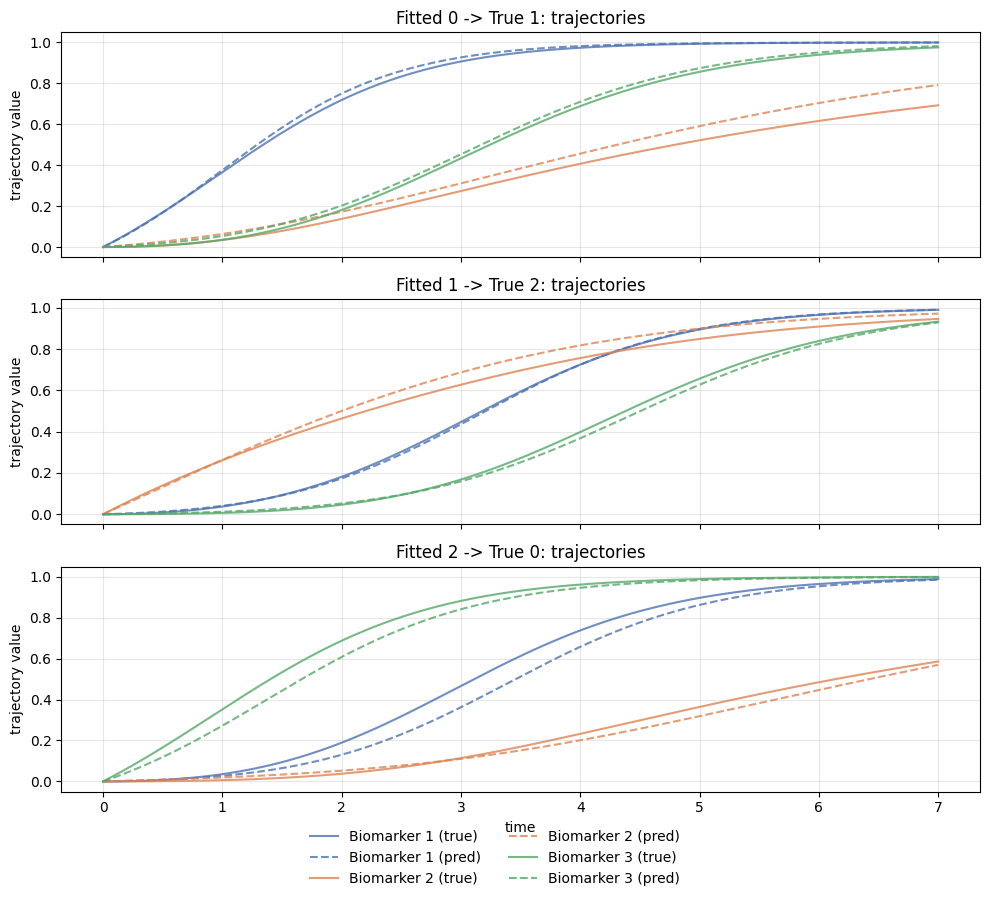

In [58]:
plot_true_vs_predicted_subtype_trajectories(
    n_subtypes=n_fitted_subtypes,
    f_true_list=f_list,
    scalar_K_true_list=scalar_K_list,
    f_pred_list=best_model.cluster_f,
    scalar_K_pred_list=[best_model.final_scalar_K] * n_fitted_subtypes,
    K=K,
    t_span=t_span,
    n_biomarkers=n_biomarkers,
    solve_system_fn=solve_system,
    subtype_mapping=subtype_mapping,
    kappa_true=true_kappa,
    kappa_pred=best_model.final_kappa,
)

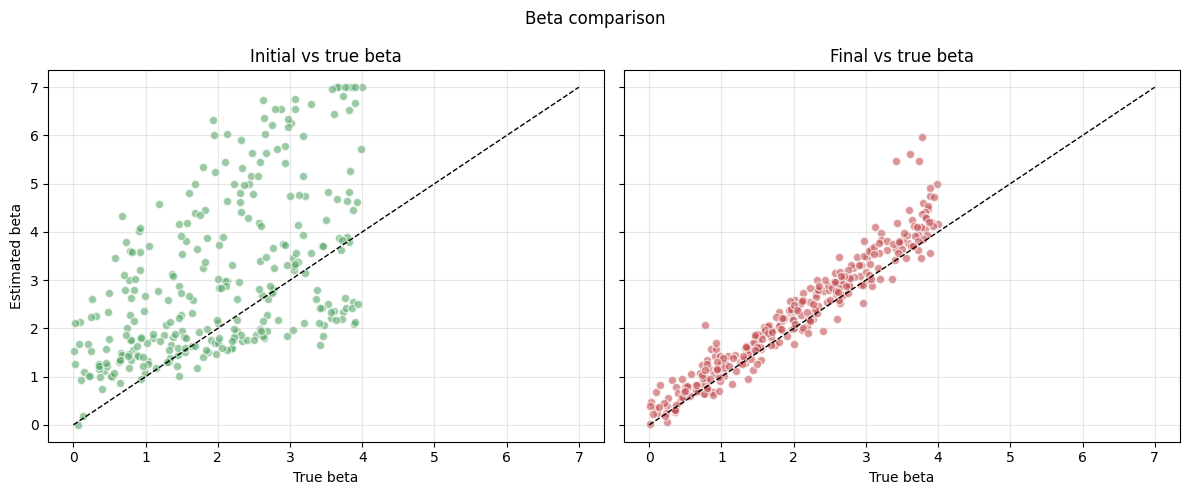

In [59]:
# Plot beta comparison (init vs final vs true)
beta_init_array = np.array([p.get("initial_beta", np.nan) for p in X_list])
if np.any(np.isnan(beta_init_array)):
    beta_init_array = initial_beta

beta_final_array = best_model.beta_history[:, -1]
plot_beta_comparison(beta_true_flat, beta_init_array, beta_final_array)


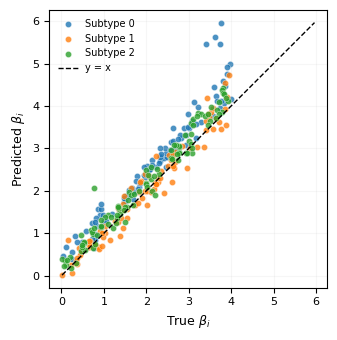

In [60]:
import matplotlib.pyplot as plt
import numpy as np

# Scatter colored by TRUE subtype (after f-based label mapping)
beta_pred = best_model.beta_history[:, -1]

fig, ax = plt.subplots(figsize=(3.5, 3.5))
colors = plt.get_cmap("tab10").colors

for k in range(n_true_subtypes):
    mask = mapped_assignments == k
    if not np.any(mask):
        continue
    ax.scatter(
        beta_true_flat[mask],
        beta_pred[mask],
        c=[colors[k % len(colors)]],
        label=f"Subtype {k}",
        s=20,
        alpha=0.8,
        edgecolors="white",
        linewidths=0.3,
    )

# Diagonal (perfect prediction)
lims = [
    min(beta_true_flat.min(), beta_pred.min()),
    max(beta_true_flat.max(), beta_pred.max()),
]
ax.plot(lims, lims, "k--", linewidth=1, label="y = x")

ax.set_xlabel(r"True $\beta_i$", fontsize=9)
ax.set_ylabel(r"Predicted $\beta_i$", fontsize=9)
ax.tick_params(axis="both", labelsize=8)
ax.set_aspect("equal")
ax.legend(fontsize=7, frameon=False)
ax.grid(True, alpha=0.1)
plt.tight_layout()
#plt.savefig("beta_true_vs_pred.pdf", bbox_inches="tight", dpi=300)
plt.show()